In [2]:
# Imports
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import re
import pandas as pd
from io import StringIO
import numpy as np

In [3]:
# Simulations settings
RUNTIME_PREDICTION = {
    "safety_factor": 0.002,
    "alpha": 2.59,
    "beta": 2.41,
}
MILP_SOLVERS = {"gurobi", "highs", "cbc", "glpk"}
RUNTIME_PREDICTION = {"safety_factor": 0.002, "alpha": 2.59, "beta": 2.41}

In [4]:
# Plots settings
SOLVER_COLORS = {
    "NearestNeighbor": "#1f77b4",  
    "ACO":             "#ff7f0e",  
    "milp":            "#2ca02c",  
    "gurobi":          "#9467bd",  
    "highs":           "#e377c2",  
    "cbc":             "#fcdf00",  
    "glpk":            "#d62728",  
}

BLUE_PALETTE = [
    "#d0e4f7",  # very light
    "#a8cce8",  # light
    "#7ab4d9",  # medium-light
    "#4682b4",  # steelblue
    "#2e5f8a",  # medium-dark
    "#1a3d61",  # dark
]

SOLVER_LABELS = {
    "NearestNeighbor": "Twnn",
    "ACO":             "Aco",
    "gurobi":          "Gurobi",
    "highs":           "HiGHS",
    "cbc":             "CBC",
    "glpk":            "GLPK",
}

SIZE_ORDER = ["small", "medium", "big", "large"]
SIZE_LABELS = {
    "small":  "Pequeño\n(c ≤ 25)",
    "medium": "Mediano\n(25 < c ≤ 50)",
    "big":    "Grande\n(50 < c ≤ 80)",
    "large":  "Muy grande\n(c > 80)",
}

SOLVER_BAR_COLORS = {
    "NearestNeighbor": ["#1f77b4", "#aec7e8"],  
    "ACO":             ["#ff7f0e", "#ffbb78"],  
    "milp":            ["#2ca02c", "#98df8a", "#4db84e"],  
    "gurobi":          ["#9467bd", "#c5b0d5"],  
    "highs":           ["#e377c2", "#f7b6d2"],  
    "cbc":             ["#fcdf00", "#fef4a0"],  
    "glpk":            ["#d62728", "#f5a09b"],  
  }

Descomentar para guardar las imagenes en /src/assay

In [10]:
# import matplotlib.pyplot as plt
# import os

# os.makedirs("figures", exist_ok=True)
# _fig_counter = [0]
# _original_show = plt.show

# def _auto_save_show():
#     _fig_counter[0] += 1
#     plt.savefig(f"/Users/tomasmarmay/Documents/famaf/tesis/src/assay/fig_{_fig_counter[0]:02d}.png", bbox_inches="tight", dpi=150)
#     _original_show()

# plt.show = _auto_save_show

In [17]:
# Load and process data

with open("../run_results.sql", "r") as f:
    sql = f.read()

# Extraer el bloque COPY de run_results
match = re.search(
    r"COPY public\.run_results \((.+?)\) FROM stdin;\n(.*?)\\\.",
    sql,
    re.DOTALL,
)

columns = [c.strip() for c in match.group(1).split(",")]
data = match.group(2)

df = pd.read_csv(StringIO(data), sep="\t", names=columns, na_values=["\\N"])
pre_filter_df = df.copy()
def filter_by_experiment_prefix(df: pd.DataFrame, prefix: str, column: str = "experiment_id") -> pd.DataFrame:
    return df[df[column].str.startswith(prefix)].copy()

def prepare_dataframe(df: pd.DataFrame):
    df = df.copy()

    def extract_C(text):
        match = re.search(r'C(\d+)', text)
        return float(match.group(1)) if match else None

    def extract_V(text):
        match = re.search(r'V(\d+)', text)
        return float(match.group(1)) if match else None

    def extract_size(c):
        if 0 < c <= 25:
            return "small"
        elif 25 < c <= 50:
            return "medium"
        elif 50 < c <= 80:
            return "big"
        else:
            return "large"

    def timeout_estimator(c, v):
        return int(RUNTIME_PREDICTION["safety_factor"] * (c ** RUNTIME_PREDICTION["alpha"]) * (v ** RUNTIME_PREDICTION["beta"]))

    def ants_it_estimator(c):
        if c <= 50:
            return 100, 100
        return 200, 300
    
    df["c"] = df["experiment_id"].apply(extract_C)
    df["v"] = df["experiment_id"].apply(extract_V)
    df["size"] = df["c"].apply(extract_size)

    c, v, n = df["c"], df["v"], (df["c"] + 2*df["v"])     
    df['dim'] = (2*c*v*n) + (3*(n**2)*v) + (2*v*c) + v
    df["feasible"] = df["feasible"].map({"t": True, "f": False, True: True, False: False})
    df["valid"] = df["valid"].map({"t": True, "f": False, True: True, False: False})

    # ants / it — solo ACO
    ants_it = df["c"].apply(lambda c: pd.Series(ants_it_estimator(c), index=["ants", "it"]))
    df["ants"] = df["solver"].apply(lambda s: None if s != "ACO" else None)  # placeholder
    df["it"]   = None
    aco_mask = df["solver"] == "ACO"
    df.loc[aco_mask, ["ants", "it"]] = ants_it[aco_mask].values

    # timeout — solo MILP
    milp_mask = df["solver"].isin(MILP_SOLVERS)
    df["timeout"] = None
    df.loc[milp_mask, "timeout"] = df.loc[milp_mask].apply(
        lambda row: timeout_estimator(row["c"], row["v"]), axis=1
    )
    return df

df = prepare_dataframe(filter_by_experiment_prefix(df=df, prefix="turing2"))

Las soluciones infactibles no generan una ruta completa, por lo que el validador no puede verificarlas y las marca como inválidas por defecto. La combinación infactible+inválido no representa un error del solver sino una limitación del proceso de validación.

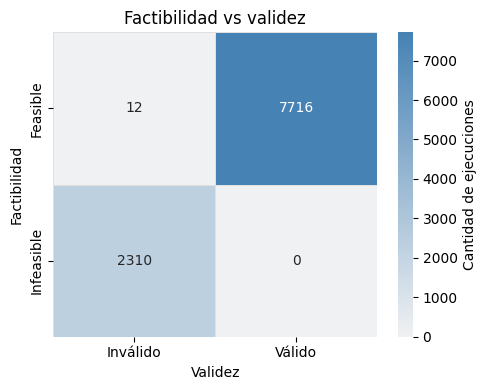

In [12]:
crosstab = pd.crosstab(
    df["feasible"].map({True: "Feasible", False: "Infeasible"}),
    df["valid"].map({True: "Válido", False: "Inválido"}),
)

fig, ax = plt.subplots(figsize=(5, 4))

sns.heatmap(
    crosstab,
    ax=ax,
    cmap=sns.light_palette("#4682b4", as_cmap=True),
    annot=True,
    fmt="d",
    linewidths=0.4,
    linecolor="#e0e0e0",
    cbar_kws={"label": "Cantidad de ejecuciones"},
)

ax.set_title("Factibilidad vs validez")
ax.set_xlabel("Validez")
ax.set_ylabel("Factibilidad")

plt.tight_layout()
plt.show()

### 5.1 Análisis individual TWNN

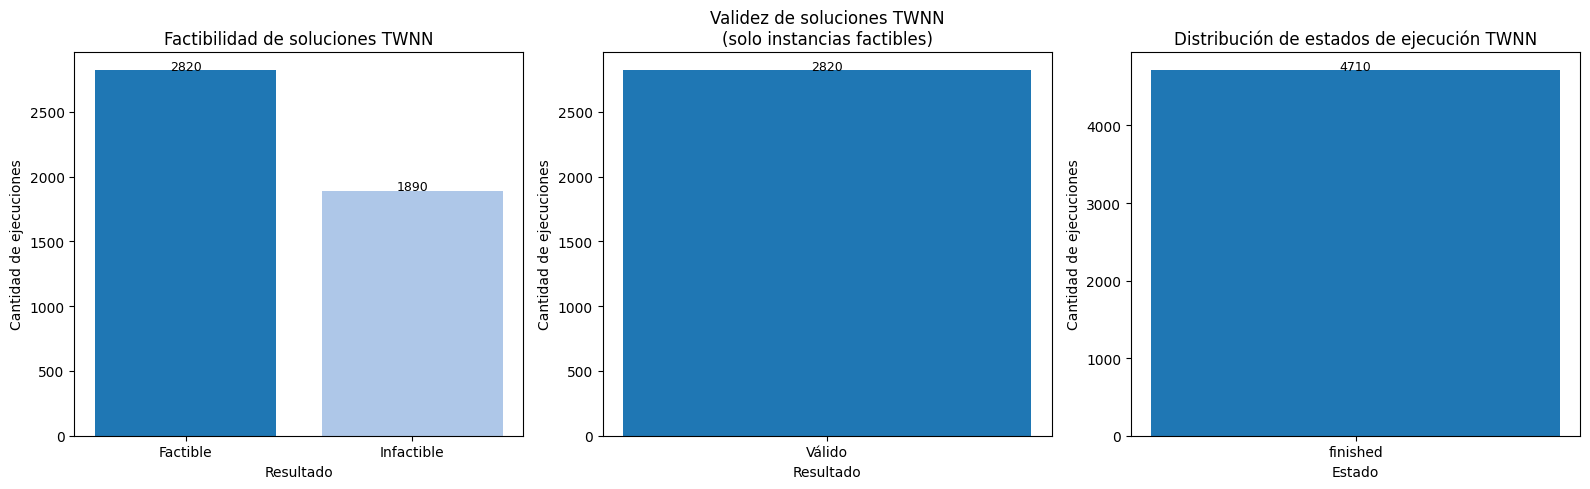

In [13]:
nn = df[df["solver"] == "NearestNeighbor"].copy()
nn_feasible = nn[nn["feasible"] == True].copy()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# ── Feasible / Infeasible ──────────────────────────────────────────────────────
feasible_counts = nn["feasible"].map({True: "Factible", False: "Infactible"}).value_counts()

axes[0].bar(feasible_counts.index, feasible_counts.values, color=SOLVER_BAR_COLORS['NearestNeighbor'])
axes[0].set_title("Factibilidad de soluciones TWNN")
axes[0].set_xlabel("Resultado")
axes[0].set_ylabel("Cantidad de ejecuciones")
for i, (label, val) in enumerate(feasible_counts.items()):
    axes[0].text(i, val + 5, str(val), ha="center", fontsize=9)

# ── Valid / Invalid (solo feasibles) ──────────────────────────────────────────
valid_counts = nn_feasible["valid"].map({True: "Válido", False: "Inválido"}).value_counts()

axes[1].bar(valid_counts.index, valid_counts.values, color=SOLVER_BAR_COLORS['NearestNeighbor'])
axes[1].set_title("Validez de soluciones TWNN\n(solo instancias factibles)")
axes[1].set_xlabel("Resultado")
axes[1].set_ylabel("Cantidad de ejecuciones")
for i, (label, val) in enumerate(valid_counts.items()):
    axes[1].text(i, val + 5, str(val), ha="center", fontsize=9)

# ── Status distribution ────────────────────────────────────────────────────────
status_counts = nn["status"].value_counts()

axes[2].bar(status_counts.index, status_counts.values, color=SOLVER_BAR_COLORS['NearestNeighbor'])
axes[2].set_title("Distribución de estados de ejecución TWNN")
axes[2].set_xlabel("Estado")
axes[2].set_ylabel("Cantidad de ejecuciones")
for i, (label, val) in enumerate(status_counts.items()):
    axes[2].text(i, val + 5, str(val), ha="center", fontsize=9)

plt.tight_layout()
plt.show()

/tmp/ipykernel_28710/2357742704.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([SIZE_LABELS[s] for s in SIZE_ORDER])


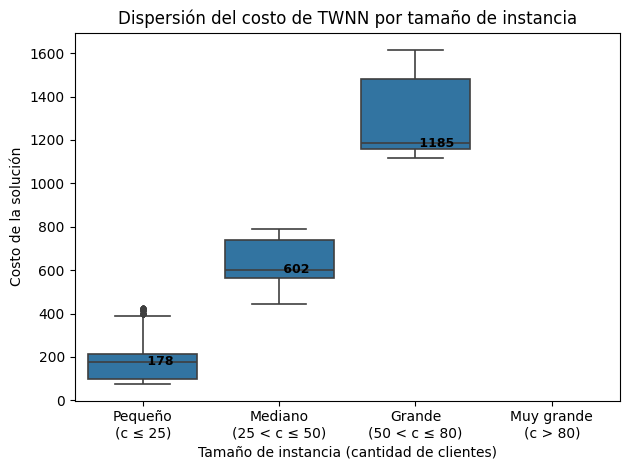

In [14]:
fig, ax = plt.subplots()

sns.boxplot(
    data=nn_feasible,
    x="size",
    y="cost",
    order=SIZE_ORDER,
    color=SOLVER_COLORS["NearestNeighbor"],
    linewidth=1.2,
    flierprops=dict(marker="o", markersize=3, alpha=0.4),
    ax=ax,
)

ax.set_title("Dispersión del costo de TWNN por tamaño de instancia")
ax.set_xlabel("Tamaño de instancia (cantidad de clientes)")
ax.set_ylabel("Costo de la solución")
ax.set_xticklabels([SIZE_LABELS[s] for s in SIZE_ORDER])

for i, size in enumerate(SIZE_ORDER):
    subset = nn_feasible[nn_feasible["size"] == size]["cost"]
    if not subset.empty:
        median = subset.median()
        ax.text(i, median, f" {median:.0f}", va="center", ha="left",
                fontsize=9, color="black", fontweight="bold")

plt.tight_layout()
plt.show()

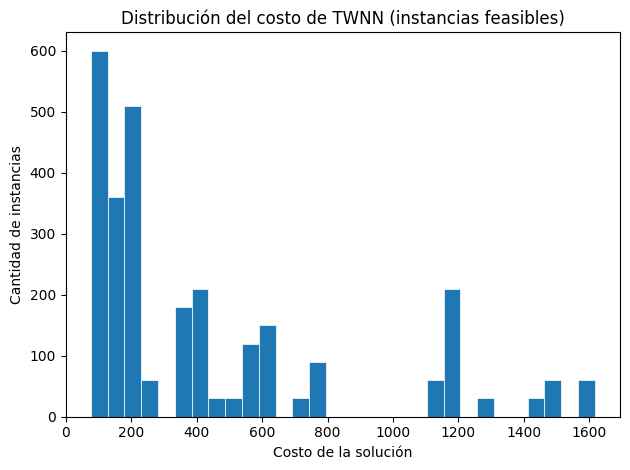

In [15]:
fig, ax = plt.subplots()
ax.hist(nn_feasible["cost"], bins=30, color=SOLVER_COLORS["NearestNeighbor"], edgecolor="white", linewidth=0.5)
ax.set_title("Distribución del costo de TWNN (instancias feasibles)")
ax.set_xlabel("Costo de la solución")
ax.set_ylabel("Cantidad de instancias")
plt.tight_layout()
plt.show()

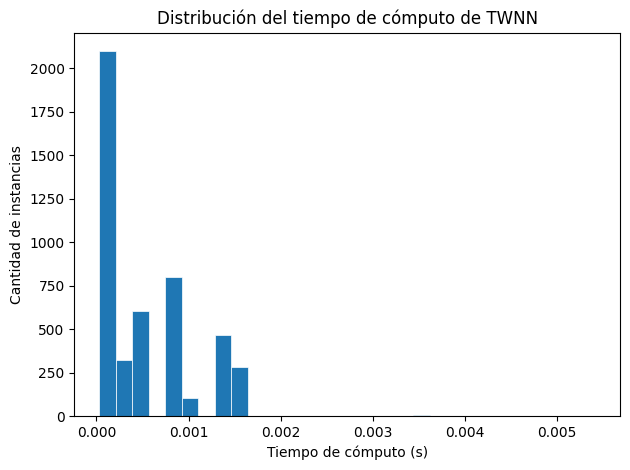

In [16]:
fig, ax = plt.subplots()
ax.hist(nn["runtime"], bins=30, color=SOLVER_COLORS["NearestNeighbor"], edgecolor="white", linewidth=0.5)
ax.set_title("Distribución del tiempo de cómputo de TWNN")
ax.set_xlabel("Tiempo de cómputo (s)")
ax.set_ylabel("Cantidad de instancias")
plt.tight_layout()
plt.show()

### 5.2 Análisis individual de ACO

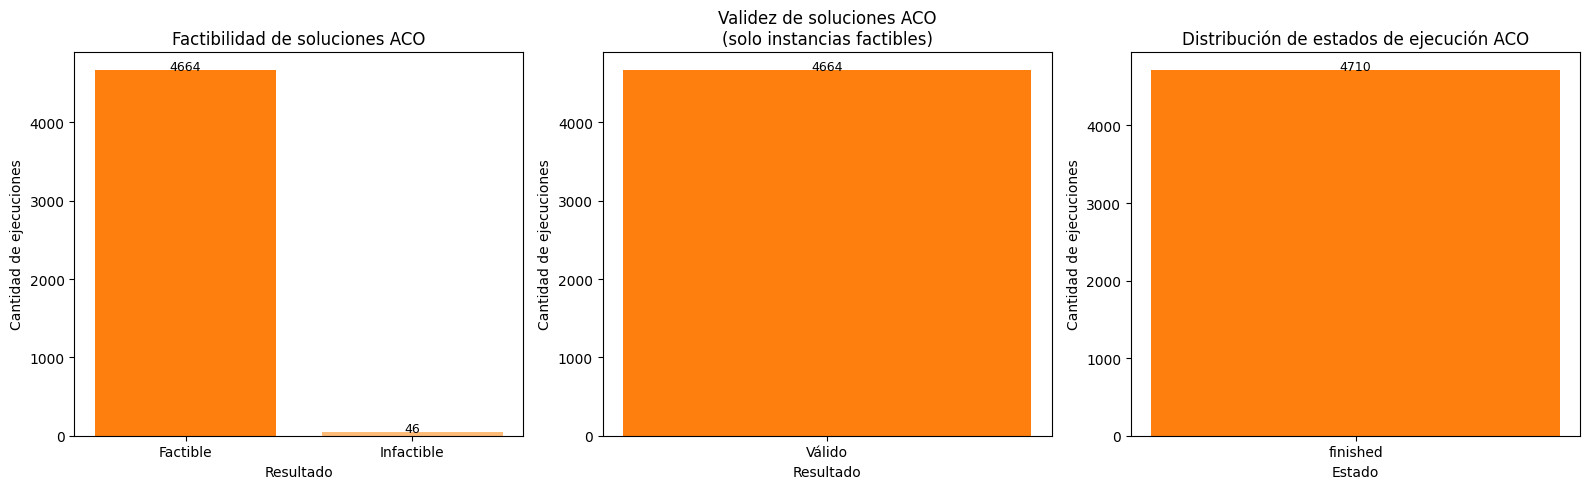

In [17]:
aco = df[df["solver"] == "ACO"].copy()
aco_feasible = aco[aco["feasible"] == True].copy()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# ── Feasible / Infeasible ──────────────────────────────────────────────────────
feasible_counts = aco["feasible"].map({True: "Factible", False: "Infactible"}).value_counts()

axes[0].bar(feasible_counts.index, feasible_counts.values, color=SOLVER_BAR_COLORS["ACO"])
axes[0].set_title("Factibilidad de soluciones ACO")
axes[0].set_xlabel("Resultado")
axes[0].set_ylabel("Cantidad de ejecuciones")
for i, (label, val) in enumerate(feasible_counts.items()):
    axes[0].text(i, val + 5, str(val), ha="center", fontsize=9)

# ── Valid / Invalid (solo feasibles) ──────────────────────────────────────────
valid_counts = aco_feasible["valid"].map({True: "Válido", False: "Inválido"}).value_counts()

axes[1].bar(valid_counts.index, valid_counts.values, color=SOLVER_BAR_COLORS["ACO"])
axes[1].set_title("Validez de soluciones ACO\n(solo instancias factibles)")
axes[1].set_xlabel("Resultado")
axes[1].set_ylabel("Cantidad de ejecuciones")
for i, (label, val) in enumerate(valid_counts.items()):
    axes[1].text(i, val + 5, str(val), ha="center", fontsize=9)

# ── Status distribution ────────────────────────────────────────────────────────
status_counts = aco["status"].value_counts()

axes[2].bar(status_counts.index, status_counts.values, color=SOLVER_BAR_COLORS["ACO"])
axes[2].set_title("Distribución de estados de ejecución ACO")
axes[2].set_xlabel("Estado")
axes[2].set_ylabel("Cantidad de ejecuciones")
for i, (label, val) in enumerate(status_counts.items()):
    axes[2].text(i, val + 5, str(val), ha="center", fontsize=9)

plt.tight_layout()
plt.show()

/tmp/ipykernel_28710/109289979.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([SIZE_LABELS[s] for s in SIZE_ORDER])


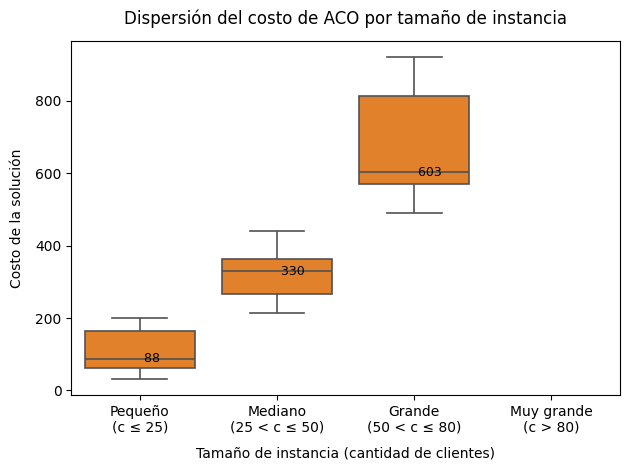

In [18]:
fig, ax = plt.subplots()

sns.boxplot(
    data=aco_feasible,
    x="size",
    y="cost",
    order=SIZE_ORDER,
    color=SOLVER_COLORS["ACO"],
    linewidth=1.2,
    flierprops=dict(marker="o", markersize=3, alpha=0.4),
    ax=ax,
)

# Labels
ax.set_title("Dispersión del costo de ACO por tamaño de instancia", pad=12)
ax.set_xlabel("Tamaño de instancia (cantidad de clientes)", labelpad=8)
ax.set_ylabel("Costo de la solución", labelpad=8)
ax.set_xticklabels([SIZE_LABELS[s] for s in SIZE_ORDER])

# Annotations: median value on top of each box
for i, size in enumerate(SIZE_ORDER):
    subset = aco_feasible[aco_feasible["size"] == size]["cost"]
    if not subset.empty:
        median = subset.median()
        ax.text(i, median, f" {median:.0f}", va="center", ha="left", fontsize=9)

plt.tight_layout()
plt.show()

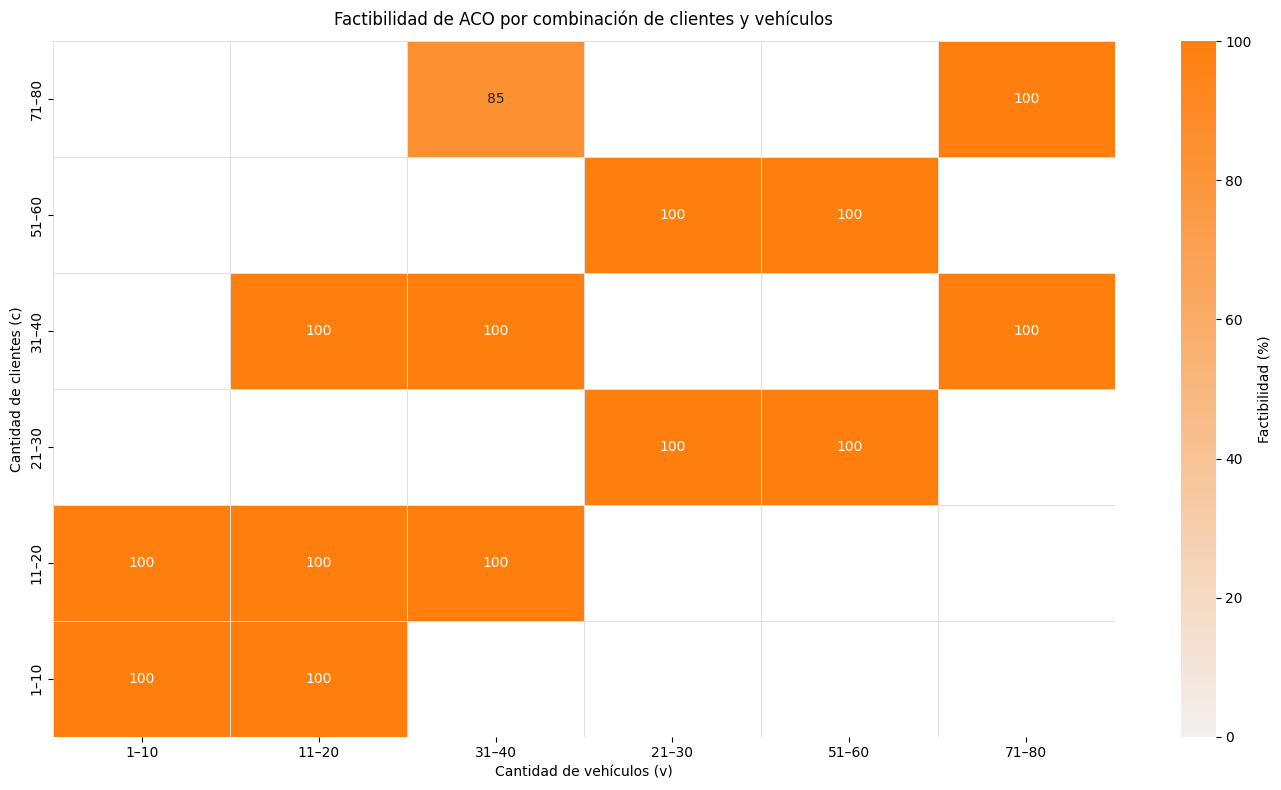

In [19]:
aco["c_bin"] = (((aco["c"] - 1) // 10) * 10 + 1).astype(int).astype(str) + "–" + (((aco["c"] - 1) // 10) * 10 + 10).astype(int).astype(str)
aco["v_bin"] = (((aco["v"] - 1) // 10) * 10 + 1).astype(int).astype(str) + "–" + (((aco["v"] - 1) // 10) * 10 + 10).astype(int).astype(str)

aco["c_mid"] = ((aco["c"] - 1) // 10) * 10 + 1
aco["v_mid"] = ((aco["v"] - 1) // 10) * 10 + 1

feasibility = (
    aco.groupby(["c_mid", "c_bin", "v_mid", "v_bin"])["feasible"]
    .mean()
    .mul(100)
    .round(1)
    .reset_index()
    .pivot(index=["c_mid", "c_bin"], columns=["v_mid", "v_bin"], values="feasible")
    .sort_index(ascending=False)
)

# Use only the label level for display
feasibility.index = feasibility.index.get_level_values("c_bin")
feasibility.columns = feasibility.columns.get_level_values("v_bin")

fig, ax = plt.subplots(figsize=(14, 8))

sns.heatmap(
    feasibility,
    ax=ax,
    cmap=sns.light_palette(SOLVER_COLORS['ACO'], as_cmap=True),
    vmin=0,
    vmax=100,
    annot=True,
    fmt=".0f",
    linewidths=0.4,
    linecolor="#e0e0e0",
    cbar_kws={"label": "Factibilidad (%)"},
)

ax.set_title("Factibilidad de ACO por combinación de clientes y vehículos", pad=12)
ax.set_xlabel("Cantidad de vehículos (v)")
ax.set_ylabel("Cantidad de clientes (c)")

plt.tight_layout()
plt.show()

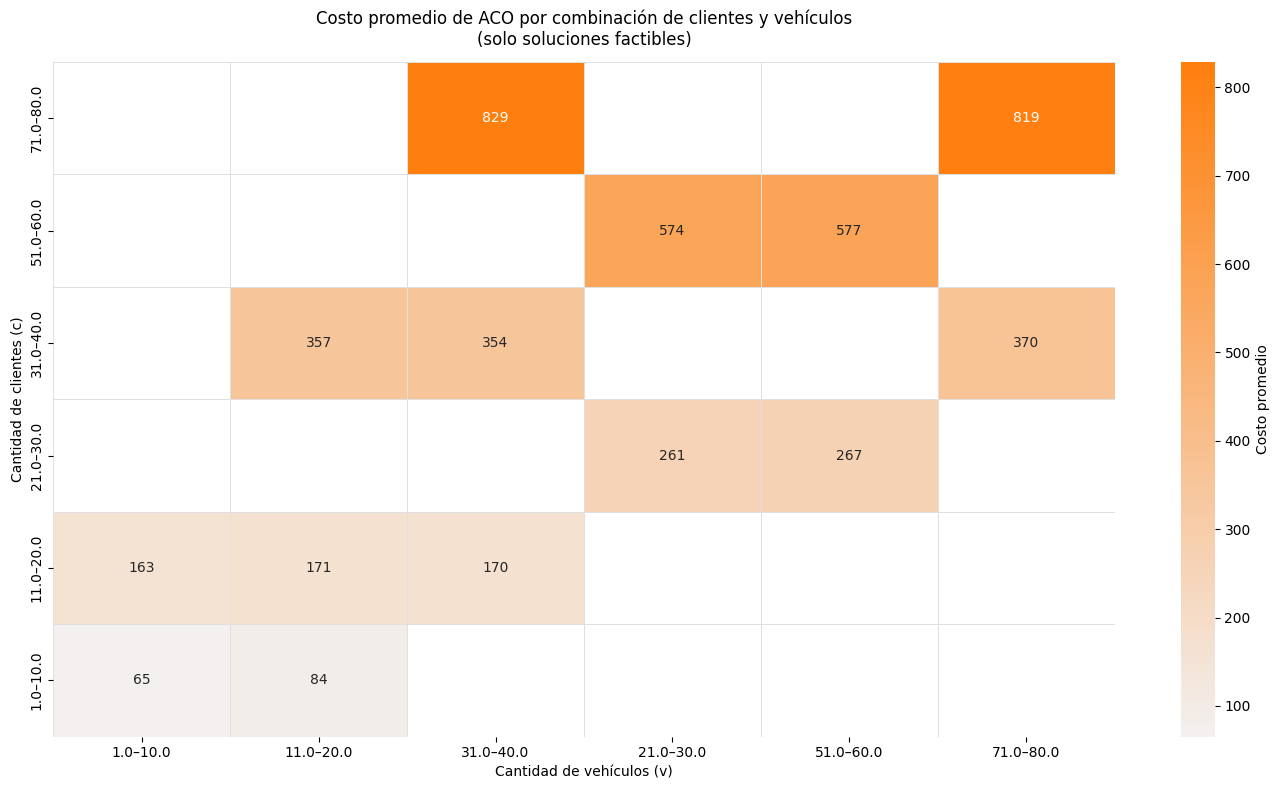

In [20]:
aco_feasible["c_mid"] = ((aco_feasible["c"] - 1) // 10) * 10 + 1
aco_feasible["v_mid"] = ((aco_feasible["v"] - 1) // 10) * 10 + 1
aco_feasible["c_bin"] = aco_feasible["c_mid"].astype(str) + "–" + (aco_feasible["c_mid"] + 9).astype(str)
aco_feasible["v_bin"] = aco_feasible["v_mid"].astype(str) + "–" + (aco_feasible["v_mid"] + 9).astype(str)

cost_pivot = (
    aco_feasible.groupby(["c_mid", "c_bin", "v_mid", "v_bin"])["cost"]
    .mean()
    .round(1)
    .reset_index()
    .pivot(index=["c_mid", "c_bin"], columns=["v_mid", "v_bin"], values="cost")
    .sort_index(ascending=False)
)

cost_pivot.index = cost_pivot.index.get_level_values("c_bin")
cost_pivot.columns = cost_pivot.columns.get_level_values("v_bin")

fig, ax = plt.subplots(figsize=(14, 8))

sns.heatmap(
    cost_pivot,
    ax=ax,
    cmap=sns.light_palette(SOLVER_COLORS['ACO'], as_cmap=True),
    annot=True,
    fmt=".0f",
    linewidths=0.4,
    linecolor="#e0e0e0",
    cbar_kws={"label": "Costo promedio"},
)

ax.set_title("Costo promedio de ACO por combinación de clientes y vehículos\n(solo soluciones factibles)", pad=12)
ax.set_xlabel("Cantidad de vehículos (v)")
ax.set_ylabel("Cantidad de clientes (c)")

plt.tight_layout()
plt.show()

muestra la naturaleza estocastica de aco

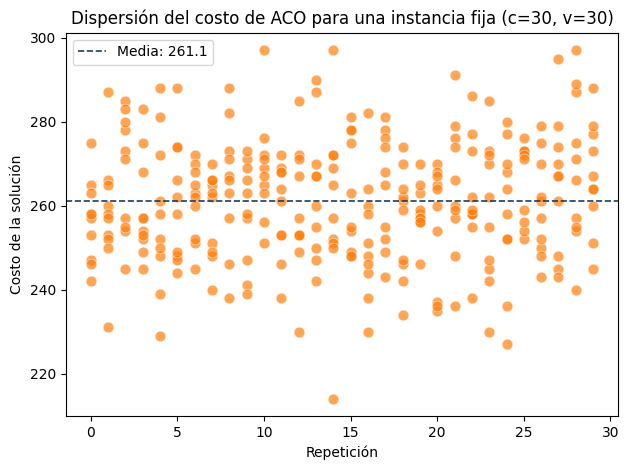

In [21]:
instance = df[
    (df["solver"] == "ACO") &
    (df["c"] == 30) &
    (df["v"] == 30) &
    (df["feasible"] == True)
].copy()

fig, ax = plt.subplots()

ax.scatter(
    instance["instance_repetition"],
    instance["cost"],
    color=SOLVER_COLORS["ACO"],
    alpha=0.7,
    edgecolors="white",
    linewidths=0.5,
    s=60,
)

ax.axhline(instance["cost"].mean(), color="#1a3d61", linestyle="--", linewidth=1.2, label=f"Media: {instance['cost'].mean():.1f}")

ax.set_title("Dispersión del costo de ACO para una instancia fija (c=30, v=30)")
ax.set_xlabel("Repetición")
ax.set_ylabel("Costo de la solución")
ax.legend()

plt.tight_layout()
plt.show()

### 5.3 Análisis individual de MILP

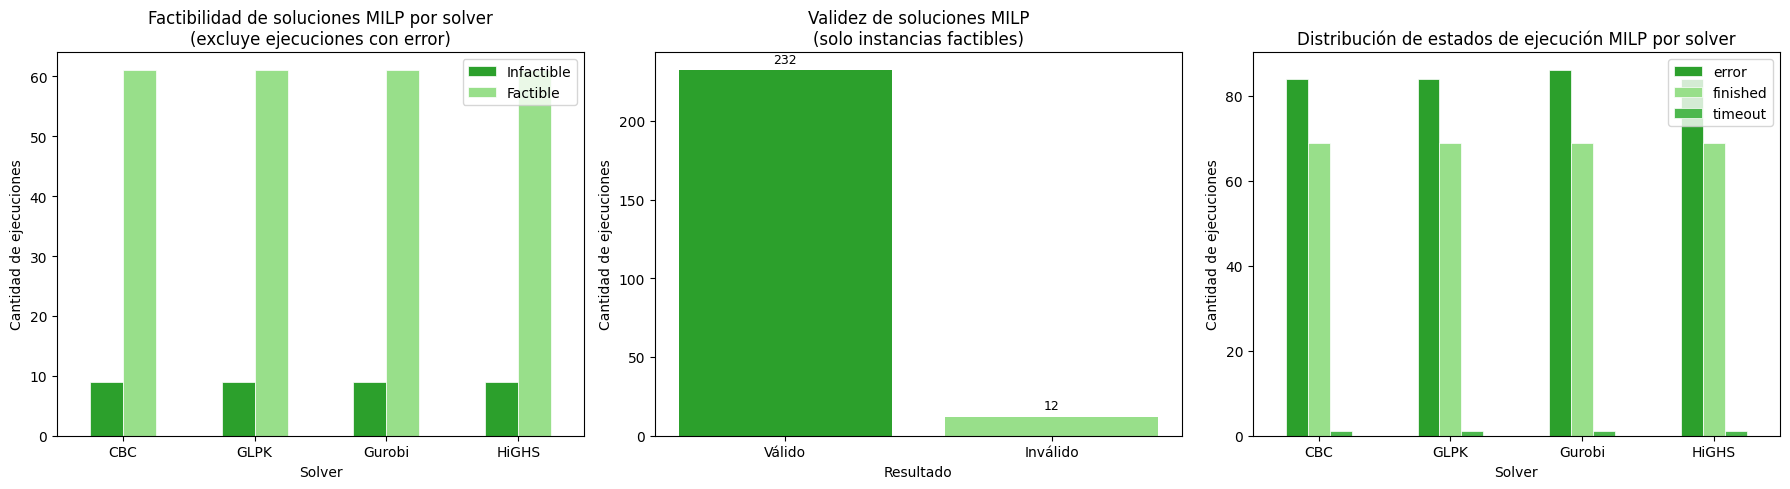

In [22]:
milp = df[df["solver"].isin(MILP_SOLVERS)].copy()
milp_feasible = milp[milp["feasible"] == True].copy()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ── Feasible / Infeasible ──────────────────────────────────────────────────────
feasibility_by_solver = (
      milp[milp["status"] != "error"]
      .groupby("solver")["feasible"]
      .value_counts()
      .unstack(fill_value=0)
      .rename(columns={True: "Factible", False: "Infactible"})
  )

feasibility_by_solver.plot(
    kind="bar",
    ax=axes[0],
    color=SOLVER_BAR_COLORS["milp"],
    edgecolor="white",
    linewidth=0.5,
)
axes[0].set_title("Factibilidad de soluciones MILP por solver\n(excluye ejecuciones con error)")
axes[0].set_xlabel("Solver")
axes[0].set_ylabel("Cantidad de ejecuciones")
axes[0].set_xticklabels([SOLVER_LABELS[s] for s in feasibility_by_solver.index], rotation=0)
axes[0].legend(title=None)

# ── Valid / Invalid (solo feasibles) ──────────────────────────────────────────
valid_counts = milp_feasible["valid"].map({True: "Válido", False: "Inválido"}).value_counts()

axes[1].bar(valid_counts.index, valid_counts.values, color=SOLVER_BAR_COLORS["milp"])
axes[1].set_title("Validez de soluciones MILP\n(solo instancias factibles)")
axes[1].set_xlabel("Resultado")
axes[1].set_ylabel("Cantidad de ejecuciones")
for i, (label, val) in enumerate(valid_counts.items()):
    axes[1].text(i, val + 5, str(val), ha="center", fontsize=9)

# ── Status distribution ────────────────────────────────────────────────────────
status_by_solver = (
    milp.groupby("solver")["status"]
    .value_counts()
    .unstack(fill_value=0)
)

status_by_solver.plot(
    kind="bar",
    ax=axes[2],
    color=SOLVER_BAR_COLORS['milp'],
    edgecolor="white",
    linewidth=0.5,
)
axes[2].set_title("Distribución de estados de ejecución MILP por solver")
axes[2].set_xlabel("Solver")
axes[2].set_ylabel("Cantidad de ejecuciones")
axes[2].set_xticklabels([SOLVER_LABELS[s] for s in status_by_solver.index], rotation=0)
axes[2].legend(title=None)

plt.tight_layout()
plt.show()

In [23]:
# Tengo que ver que pasa aca
milp_feasible[(milp_feasible['valid'] ==False) & (milp_feasible['feasible']==True)]

,id,experiment_id,instance_id,instance_repetition,solver,status,feasible,cost,runtime,routes,not_visited,created_at,valid,c,v,size,dim,ants,it,timeout
507670,508247,turing2_C5_V10__seed42__git81b49ed,turing2_C5_V10__seed42__git81b49ed__i1,0,gurobi,finished,True,37,2.494672,"{""7"": [7, 1, 2, 0, 19, 18, 10, 4, 21, 3, 17]}",[],2026-03-30 17:37:07.644209,False,5.0,10.0,small,21360.0,None,None,33
507671,508248,turing2_C5_V10__seed42__git81b49ed,turing2_C5_V10__seed42__git81b49ed__i1,0,highs,finished,True,37,2.491055,"{""7"": [7, 1, 2, 0, 19, 18, 10, 4, 21, 3, 17]}",[],2026-03-30 17:37:10.150091,False,5.0,10.0,small,21360.0,None,None,33
507672,508249,turing2_C5_V10__seed42__git81b49ed,turing2_C5_V10__seed42__git81b49ed__i1,0,cbc,finished,True,37,2.502406,"{""7"": [7, 1, 2, 0, 19, 18, 10, 4, 21, 3, 17]}",[],2026-03-30 17:37:12.656645,False,5.0,10.0,small,21360.0,None,None,33
507673,508250,turing2_C5_V10__seed42__git81b49ed,turing2_C5_V10__seed42__git81b49ed__i1,0,glpk,finished,True,37,2.502713,"{""7"": [7, 1, 2, 0, 19, 18, 10, 4, 21, 3, 17]}",[],2026-03-30 17:37:15.162957,False,5.0,10.0,small,21360.0,None,None,33
507798,508375,turing2_C5_V10__seed42__git81b49ed,turing2_C5_V10__seed42__git81b49ed__i3,0,gurobi,finished,True,33,4.015803,"{""12"": [12, 2, 4, 7, 19, 1, 3, 0, 13, 22]}",[],2026-03-30 17:38:07.245877,False,5.0,10.0,small,21360.0,None,None,33
507799,508376,turing2_C5_V10__seed42__git81b49ed,turing2_C5_V10__seed42__git81b49ed__i3,0,highs,finished,True,33,3.994649,"{""12"": [12, 2, 4, 7, 19, 1, 3, 0, 13, 22]}",[],2026-03-30 17:38:11.246914,False,5.0,10.0,small,21360.0,None,None,33
507800,508377,turing2_C5_V10__seed42__git81b49ed,turing2_C5_V10__seed42__git81b49ed__i3,0,cbc,finished,True,33,3.988011,"{""12"": [12, 2, 4, 7, 19, 1, 3, 0, 13, 22]}",[],2026-03-30 17:38:15.241395,False,5.0,10.0,small,21360.0,None,None,33
507801,508378,turing2_C5_V10__seed42__git81b49ed,turing2_C5_V10__seed42__git81b49ed__i3,0,glpk,finished,True,33,4.016449,"{""12"": [12, 2, 4, 7, 19, 1, 3, 0, 13, 22]}",[],2026-03-30 17:38:19.262619,False,5.0,10.0,small,21360.0,None,None,33
508120,508695,turing2_C5_V10__seed42__git81b49ed,turing2_C5_V10__seed42__git81b49ed__i8,0,gurobi,finished,True,31,3.731465,"{""12"": [12, 3, 20, 0, 23, 4, 1, 2, 19, 13, 22]}",[],2026-03-30 17:40:38.615114,False,5.0,10.0,small,21360.0,None,None,33
508121,508696,turing2_C5_V10__seed42__git81b49ed,turing2_C5_V10__seed42__git81b49ed__i8,0,highs,finished,True,31,3.750782,"{""12"": [12, 3, 20, 0, 23, 4, 1, 2, 19, 13, 22]}",[],2026-03-30 17:40:42.371347,False,5.0,10.0,small,21360.0,None,None,33


/tmp/ipykernel_28710/3019020638.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_28710/3019020638.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([SOLVER_LABELS[s] for s in MILP_SOLVERS], rotation=15, ha="right")


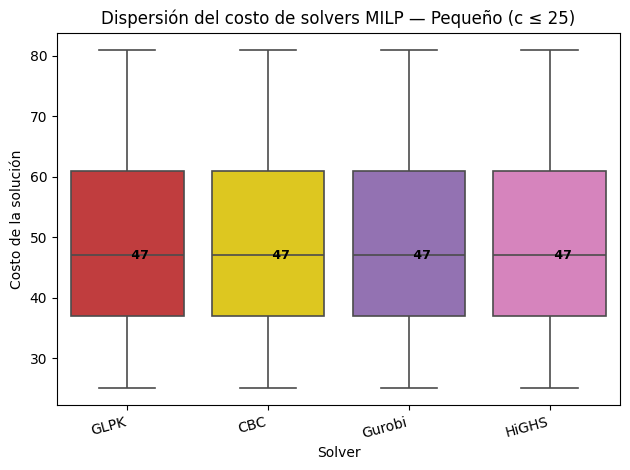

In [24]:
milp_feasible = milp[milp["feasible"] == True].copy()
sizes_present = [s for s in SIZE_ORDER if s in milp_feasible["size"].unique()]

for size in sizes_present:
    subset = milp_feasible[milp_feasible["size"] == size]

    fig, ax = plt.subplots()

    sns.boxplot(
        data=subset,
        x="solver",
        y="cost",
        order=list(MILP_SOLVERS),
        palette={s: SOLVER_COLORS[s] for s in MILP_SOLVERS},
        linewidth=1.2,
        flierprops=dict(marker="o", markersize=3, alpha=0.4),
        ax=ax,
    )

    ax.set_title(f"Dispersión del costo de solvers MILP — {SIZE_LABELS[size].replace(chr(10), ' ')}")
    ax.set_xlabel("Solver")
    ax.set_ylabel("Costo de la solución")
    ax.set_xticklabels([SOLVER_LABELS[s] for s in MILP_SOLVERS], rotation=15, ha="right")

    for i, solver in enumerate(MILP_SOLVERS):
        s_data = subset[subset["solver"] == solver]["cost"]
        if not s_data.empty:
            median = s_data.median()
            ax.text(i, median, f" {median:.0f}", va="center", ha="left", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

Solo hay en small porque para el resto hay error por ram

/tmp/ipykernel_28710/599220692.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


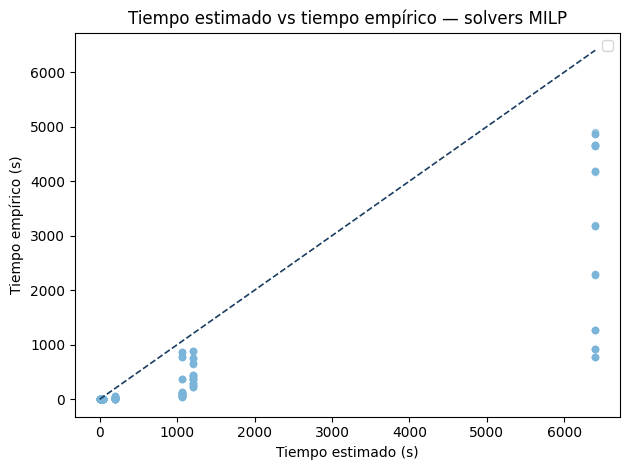

In [25]:
milp_finished = milp[milp["status"] == "finished"].copy()

fig, ax = plt.subplots()

ax.scatter(
    milp_finished["timeout"],
    milp_finished["runtime"],
    color=BLUE_PALETTE[2],
    alpha=0.6,
    s=20,
)

# Diagonal y=x
lim = max(milp_finished["timeout"].max(), milp_finished["runtime"].max())
ax.plot([0, lim], [0, lim], color=BLUE_PALETTE[5], linewidth=1.2, linestyle="--")

ax.set_title("Tiempo estimado vs tiempo empírico — solvers MILP")
ax.set_xlabel("Tiempo estimado (s)")
ax.set_ylabel("Tiempo empírico (s)")
ax.legend()

plt.tight_layout()
plt.show()

puedo mejorar la formula con todos los ejemplos nuevos (solo filtrar por feasible=True y con eso tener un mejor modelo y volver a hacer este grafico)

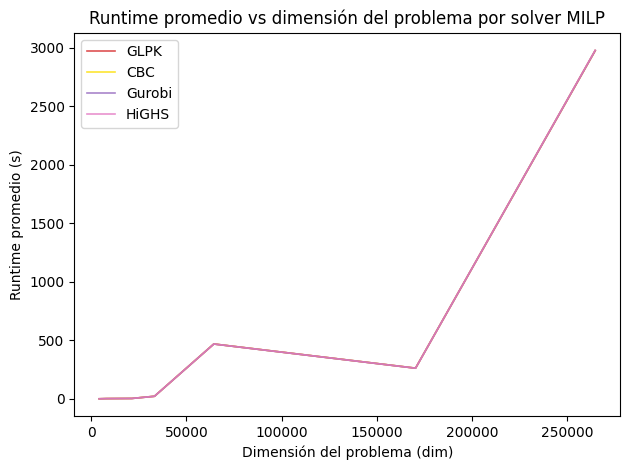

In [26]:
milp_finished = milp[milp["status"] == "finished"].copy()

runtime_by_dim = (
    milp_finished.groupby(["solver", "dim"])["runtime"]
    .mean()
    .reset_index()
)

fig, ax = plt.subplots()

for solver in MILP_SOLVERS:
    subset = runtime_by_dim[runtime_by_dim["solver"] == solver].sort_values("dim")
    ax.plot(
        subset["dim"],
        subset["runtime"],
        color=SOLVER_COLORS[solver],
        linewidth=1.2,
        label=SOLVER_LABELS[solver],
        alpha=0.8,
    )

ax.set_title("Runtime promedio vs dimensión del problema por solver MILP")
ax.set_xlabel("Dimensión del problema (dim)")
ax.set_ylabel("Runtime promedio (s)")
ax.legend()

plt.tight_layout()
plt.show()

### Con este puedo ver el punto de quiebre

/tmp/ipykernel_28710/2378458181.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  milp_all.groupby(["solver", "dim_bin"])
/tmp/ipykernel_28710/2378458181.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: (x["status"] == "error").mean() * 100)


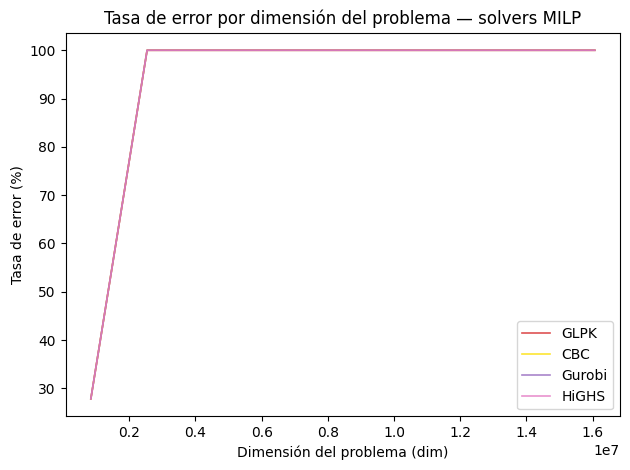

In [27]:
milp_all = df[df["solver"].isin(MILP_SOLVERS)].copy()

milp_all["dim_bin"] = pd.cut(milp_all["dim"], bins=10)

error_rate = (
    milp_all.groupby(["solver", "dim_bin"])
    .apply(lambda x: (x["status"] == "error").mean() * 100)
    .reset_index(name="error_rate")
)

error_rate["dim_mid"] = error_rate["dim_bin"].apply(lambda x: x.mid)

fig, ax = plt.subplots()

for solver in MILP_SOLVERS:
    subset = error_rate[error_rate["solver"] == solver].sort_values("dim_mid")
    ax.plot(
        subset["dim_mid"],
        subset["error_rate"],
        color=SOLVER_COLORS[solver],
        linewidth=1.2,
        label=SOLVER_LABELS[solver],
        alpha=0.8,
    )

ax.set_title("Tasa de error por dimensión del problema — solvers MILP")
ax.set_xlabel("Dimensión del problema (dim)")
ax.set_ylabel("Tasa de error (%)")
ax.legend()

plt.tight_layout()
plt.show()

###   5.4 Comparación general

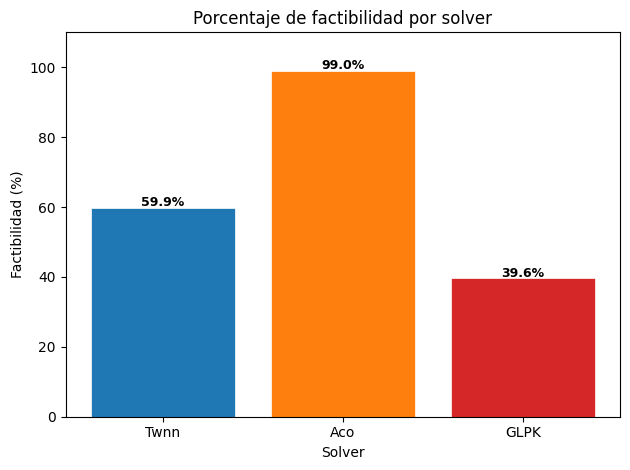

In [28]:
glpk_feasible = df[(df["solver"] == "glpk") & (df["feasible"] == True)].copy()
aco_feasible = df[(df["solver"] == "ACO") & (df["feasible"] == True)].copy()
nn_feasible = df[(df["solver"] == "NearestNeighbor") & (df["feasible"] == True)].copy()

solvers_feasibility = {
    "NearestNeighbor": nn_feasible,
    "ACO": aco_feasible,
    "glpk": glpk_feasible,
}

feasibility_pct = {
    solver: (df[df["solver"] == solver]["feasible"].mean() * 100)
    for solver in ["NearestNeighbor", "ACO", "glpk"]
}

fig, ax = plt.subplots()

ax.bar(
    [SOLVER_LABELS[s] for s in feasibility_pct],
    feasibility_pct.values(),
    color=[SOLVER_COLORS[s] for s in feasibility_pct],
    edgecolor="white",
    linewidth=0.5,
)

for i, (solver, pct) in enumerate(feasibility_pct.items()):
    ax.text(i, pct + 0.5, f"{pct:.1f}%", ha="center", fontsize=9, fontweight="bold")

ax.set_title("Porcentaje de factibilidad por solver")
ax.set_xlabel("Solver")
ax.set_ylabel("Factibilidad (%)")
ax.set_ylim(0, 110)

plt.tight_layout()
plt.show()

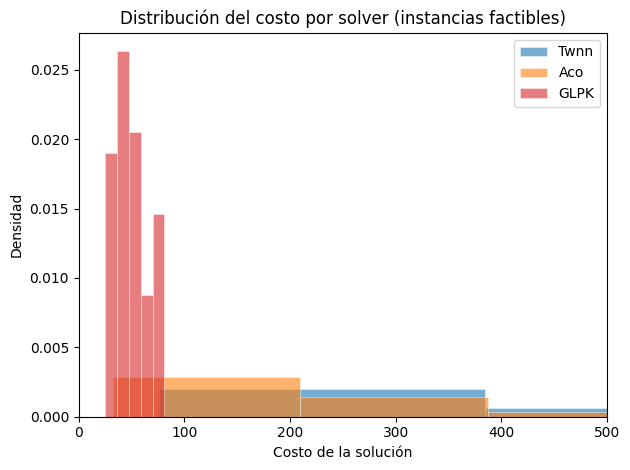

In [29]:
fig, ax = plt.subplots()

for solver, data in solvers_feasibility.items():
    ax.hist(
        data["cost"],
        bins=5,
        color=SOLVER_COLORS[solver],
        edgecolor="white",
        linewidth=0.5,
        alpha=0.6,
        density=True,
        label=SOLVER_LABELS[solver],
    )

ax.set_title("Distribución del costo por solver (instancias factibles)")
ax.set_xlabel("Costo de la solución")
ax.set_ylabel("Densidad")
ax.legend()
ax.set_xlim(0, 500)

plt.tight_layout()
plt.show()

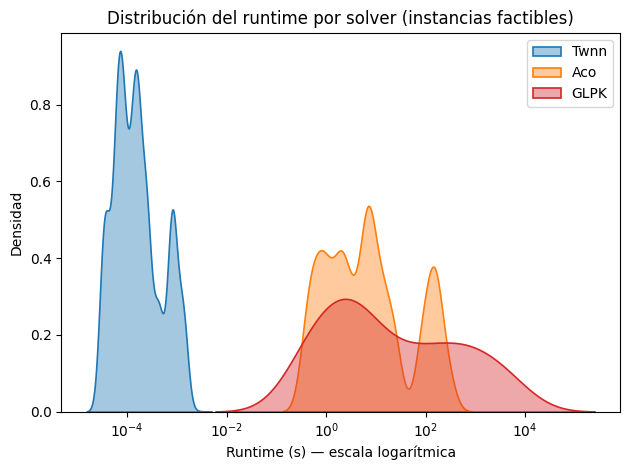

In [30]:
fig, ax = plt.subplots()

for solver, data in solvers_feasibility.items():
    sns.kdeplot(
        data["runtime"],
        ax=ax,
        color=SOLVER_COLORS[solver],
        fill=True,
        alpha=0.4,
        linewidth=1.2,
        label=SOLVER_LABELS[solver],
        log_scale=True,
    )

ax.set_title("Distribución del runtime por solver (instancias factibles)")
ax.set_xlabel("Runtime (s) — escala logarítmica")
ax.set_ylabel("Densidad")
ax.legend()

plt.tight_layout()
plt.show()

/tmp/ipykernel_28710/1528474930.py:17: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(


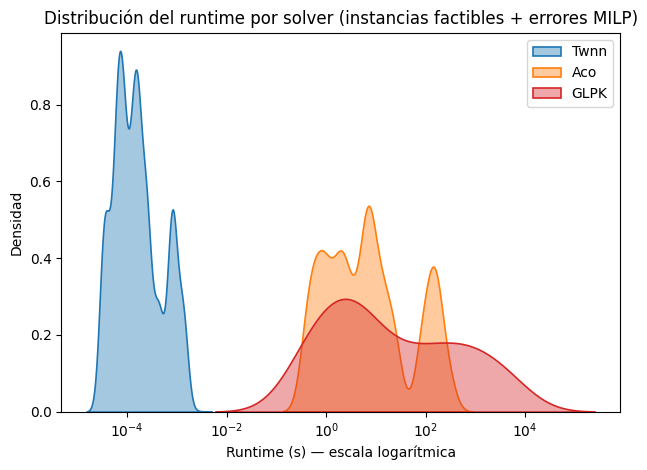

In [31]:
milp_error = milp_error = df[(df["solver"] == "glpk") & (df["status"] == "error")].copy()

fig, ax = plt.subplots()

for solver, data in solvers_feasibility.items():
    sns.kdeplot(
        data["runtime"],
        ax=ax,
        color=SOLVER_COLORS[solver],
        fill=True,
        alpha=0.4,
        linewidth=1.2,
        label=SOLVER_LABELS[solver],
        log_scale=True,
    )

sns.kdeplot(
    milp_error["runtime"],
    ax=ax,
    color='pink',
    fill=False,
    alpha=0.8,
    linewidth=1.2,
    linestyle="--",
    label="MILP — error (RAM)",
    log_scale=True,
)

ax.set_title("Distribución del runtime por solver (instancias factibles + errores MILP)")
ax.set_xlabel("Runtime (s) — escala logarítmica")
ax.set_ylabel("Densidad")
ax.legend()

plt.tight_layout()
plt.show()

Aca milp no se va mas a la derecha porque esta graficando solo las instancias chicas porque para las otras son infeasible
Estaria bueno guardar cual es el runtime antes del crash de la ram

/tmp/ipykernel_28710/2831231456.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


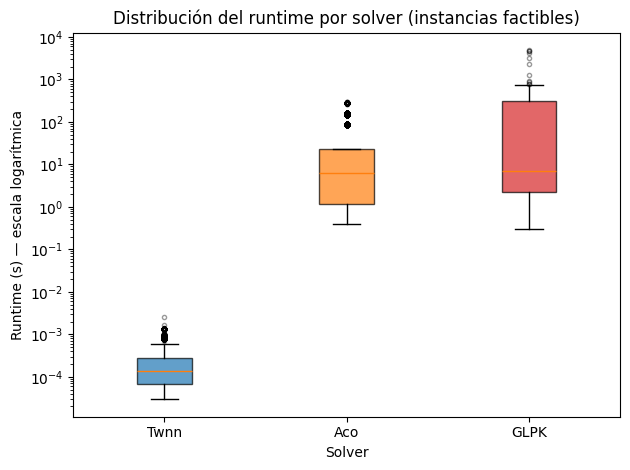

In [ ]:
fig, ax = plt.subplots()

solvers_data = [
    ("NearestNeighbor", nn_feasible),
    ("ACO", aco_feasible),
    ("glpk", glpk_feasible),
]

data_list = [data["runtime"] for _, data in solvers_data]
labels = [SOLVER_LABELS[solver] for solver, _ in solvers_data]
colors = [SOLVER_COLORS[solver] for solver, _ in solvers_data]

bp = ax.boxplot(
    data_list,
    labels=labels,
    patch_artist=True,
    flierprops=dict(marker="o", markersize=3, alpha=0.4),
)

for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_yscale("log")
ax.set_title("Distribución del runtime por solver (instancias factibles)")
ax.set_xlabel("Solver")
ax.set_ylabel("Runtime (s) — escala logarítmica")

plt.tight_layout()
plt.show()

/tmp/ipykernel_28710/1633440673.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


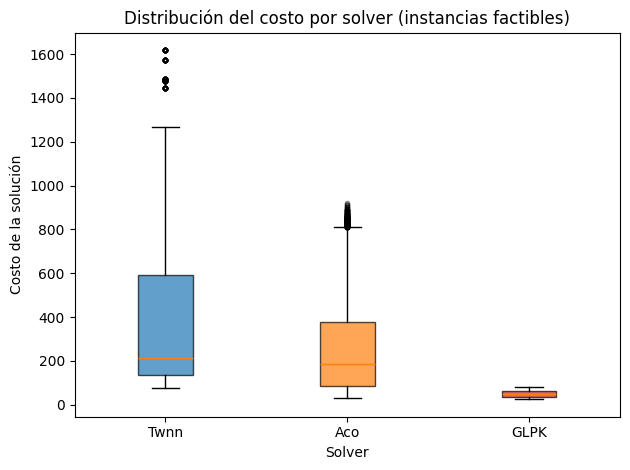

In [33]:
fig, ax = plt.subplots()

data_list = [data["cost"] for _, data in solvers_data]
labels = [SOLVER_LABELS[solver] for solver, _ in solvers_data]
colors = [SOLVER_COLORS[solver] for solver, _ in solvers_data]

bp = ax.boxplot(
    data_list,
    labels=labels,
    patch_artist=True,
    flierprops=dict(marker="o", markersize=3, alpha=0.4),
)

for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_title("Distribución del costo por solver (instancias factibles)")
ax.set_xlabel("Solver")
ax.set_ylabel("Costo de la solución")

plt.tight_layout()
plt.show()

- ¿cuánto se pierde en calidad usando una heurística en vez del óptimo?". Es el argumento central.
    - Para hacerlo bien necesitás emparejar instancias — comparar ACO y TWNN contra GLPK en la misma instancia donde los tres encontraron solución factible.
    - gap = (costo_heuristica - costo_milp) / costo_milp * 100
    - para aco tomo la menor solucion

El óptimo MILP es la solución que encuentra GLPK — como es un solver exacto, garantiza (o se aproxima mucho) a la solución óptima del problema. La línea
punteada en 0 representa ese óptimo.

El gap mide cuánto más caro es el costo de ACO o TWNN comparado con ese óptimo:

- gap = 0% → la heurística encontró exactamente la misma solución que MILP
- gap = 20% → la heurística encontró una solución un 20% más cara que el óptimo
- gap < 0% → la heurística encontró una solución más barata que MILP (no debería pasar si MILP es verdaderamente óptimo, pero puede ocurrir si MILP no llegó al
óptimo por el timeout)

El boxplot muestra la distribución de ese gap sobre todas las instancias comparables — la caja es donde cae el 50% central de los casos, la línea del medio es
la mediana. Si la caja está cerca del 0 significa que la heurística es consistentemente cercana al óptimo.

/tmp/ipykernel_28710/3445791984.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


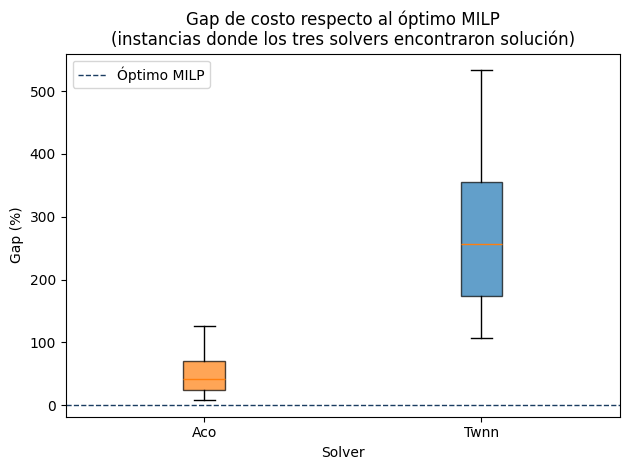

Aco: media=52.2%, std=32.8%, mediana=41.2%
Twnn: media=266.5%, std=108.8%, mediana=257.4%


In [34]:
# Instancias donde glpk terminó y encontró solución factible
glpk_ok = df[(df["solver"] == "glpk") & (df["status"] == "finished") & (df["feasible"] == True)][["instance_id", "cost"]].rename(columns={"cost": "cost_milp"})

# Mejor costo de ACO por instancia
aco_best = df[(df["solver"] == "ACO") & (df["feasible"] == True)].groupby("instance_id")["cost"].min().reset_index().rename(columns={"cost": "cost_aco"})

# Costo de TWNN por instancia
nn_ok = df[(df["solver"] == "NearestNeighbor") & (df["feasible"] == True)][["instance_id", "cost"]].rename(columns={"cost": "cost_nn"})

# Join sobre instancias comunes
gap_df = glpk_ok.merge(aco_best, on="instance_id").merge(nn_ok, on="instance_id")

gap_df["gap_aco"] = (gap_df["cost_aco"] - gap_df["cost_milp"]) / gap_df["cost_milp"] * 100
gap_df["gap_nn"]  = (gap_df["cost_nn"]  - gap_df["cost_milp"]) / gap_df["cost_milp"] * 100

# Boxplot
fig, ax = plt.subplots()

bp = ax.boxplot(
    [gap_df["gap_aco"], gap_df["gap_nn"]],
    labels=[SOLVER_LABELS["ACO"], SOLVER_LABELS["NearestNeighbor"]],
    patch_artist=True,
    flierprops=dict(marker="o", markersize=3, alpha=0.4),
)

for patch, color in zip(bp["boxes"], [SOLVER_COLORS["ACO"], SOLVER_COLORS["NearestNeighbor"]]):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.axhline(0, color="#1a3d61", linestyle="--", linewidth=1, label="Óptimo MILP")
ax.set_title("Gap de costo respecto al óptimo MILP\n(instancias donde los tres solvers encontraron solución)")
ax.set_xlabel("Solver")
ax.set_ylabel("Gap (%)")
ax.legend()

plt.tight_layout()
plt.show()

# Dato resumido
for col, solver in [("gap_aco", "ACO"), ("gap_nn", "NearestNeighbor")]:
    print(f"{SOLVER_LABELS[solver]}: media={gap_df[col].mean():.1f}%, std={gap_df[col].std():.1f}%, mediana={gap_df[col].median():.1f}%")

5.5 Que pasaria

In [35]:
# import time
# import sys
# sys.path.insert(0, '..')

# from data.generators.synthetic import SyntheticGenerator
# from solvers.aco import ACOSolver

# cfg_experiment = {
#     'num_customers': 20,
#     'num_vehicles': 20,
#     'capacity': [100],
#     'vehicle_penalty': 0,
#     'customer_demand': 1,
#     'seed': 42,
# }
# cfg_generator = {
#     'cost_range': 'low',
#     'tw_tightness': 'loose',
#     'matrix_costs_ranges': {'low': [1, 20], 'high': [100, 200], 'high_dispersion': [1, 300]},
#     'time_windows_tightness': {'loose': [0, 500], 'tight': [0, 20], 'critical': [0, 7]},
#     'time_windows_values': [5, 10],
# }

# gen = SyntheticGenerator(cfg_experiment=cfg_experiment, cfg_generator=cfg_generator)
# instance = gen.generate()

# avg_aco_ref  = df[(df['solver'] == 'ACO') & (df['c'] == 13) & (df['v'] == 19)]['runtime'].mean()
# avg_milp_ref = df[(df['solver'].isin(MILP_SOLVERS)) & (df['c'] == 13) & (df['v'] == 19)]['runtime'].mean()
# milp_cost    = df[(df['solver'].isin(MILP_SOLVERS)) & (df['c'] == 13) & (df['v'] == 19)]['cost'].mean()

# budgets = {
#     '1x ACO':     avg_aco_ref,
#     '2x ACO':     2 * avg_aco_ref,
#     '5x ACO':     5 * avg_aco_ref,
#     'MILP avg/2': avg_milp_ref / 2,
# }
# print("Presupuestos de tiempo:", {k: f"{v:.2f}s" for k, v in budgets.items()})

# def run_aco(instance, cfg_aco, max_budget):
#     cumulative_time = 0
#     best_cost = float('inf')
#     history = []
#     solver = ACOSolver(cfg_aco=cfg_aco)
#     while cumulative_time < max_budget:
#         t0 = time.time()
#         sol = solver.solve(instance)
#         elapsed = time.time() - t0
#         cumulative_time += elapsed
#         if sol.feasible and sol.total_cost < best_cost:
#             best_cost = sol.total_cost
#         history.append((cumulative_time, best_cost))
#     return history

# base_iters = 100 if instance.CUSTOMERS <= 50 else 300

# cfg_aco_base = {
#     'num_ants': 100 if instance.CUSTOMERS <= 50 else 200,
#     'num_iter': base_iters,
#     'alpha': 1.9, 'beta': 1.3, 'rho': 0.4,
#     'lambda': 5, 'gamma': 2, 'penalty': 0,
#     'phe': 100, 'tau_max': 10, 'tau_min': 1e-4,
# }
# cfg_aco_more = {**cfg_aco_base, 'num_iter': base_iters + 200}

# max_budget = avg_milp_ref / 2
# history_base = run_aco(instance, cfg_aco_base, max_budget)
# history_more = run_aco(instance, cfg_aco_more, max_budget)

# fig, ax = plt.subplots()

# for history, label, color in [
#     (history_base, f'ACO ({base_iters} iteraciones)',        BLUE_PALETTE[2]),
#     (history_more, f'ACO ({base_iters + 200} iteraciones)',  BLUE_PALETTE[4]),
# ]:
#     times, costs = zip(*history)
#     ax.step(times, costs, where='post', color=color, linewidth=1.5, label=label)

# ax.axhline(milp_cost, color=SOLVER_COLORS["glpk"], linestyle='--', linewidth=1.2, label='Costo promedio MILP')

# for label, budget in budgets.items():
#     ax.axvline(budget, linestyle=':', color='gray', alpha=0.7)
#     ax.text(budget, ax.get_ylim()[1], label, rotation=90, fontsize=8,
#             va='top', ha='right', color='gray')

# ax.set_xlabel('Tiempo acumulado (s)')
# ax.set_ylabel('Mejor costo encontrado')
# ax.set_title('Evolución del mejor costo de ACO según tiempo — c=13, v=19')
# ax.legend()

# plt.tight_layout()
# plt.show()

In [36]:
# usa esto: 
# cfg_aco = {
#     'num_ants': trial.suggest_int('num_ants', 50, 300),
#     'num_iter': trial.suggest_int('num_iter', 50, 500),
#     'alpha':    trial.suggest_float('alpha', 0.5, 3.0),
#     'beta':     trial.suggest_float('beta', 0.5, 5.0),
#     'rho':      trial.suggest_float('rho', 0.1, 0.9),
#     'phe':      trial.suggest_float('phe', 10, 500),
#     'lambda':   trial.suggest_int('lambda', 1, 20),
#     # fijos
#     'gamma': 2, 'penalty': 0, 'tau_max': 10, 'tau_min': 1e-4,
# }

In [37]:
# best_cost_base = min(cost for _, cost in history_base if cost < float('inf'))
# best_cost_more = min(cost for _, cost in history_more if cost < float('inf'))

# gap_base = (best_cost_base - milp_cost) / milp_cost * 100
# gap_more = (best_cost_more - milp_cost) / milp_cost * 100

# print(f"ACO ({base_iters} iter):       costo={best_cost_base:.1f}, gap={gap_base:.1f}%")
# print(f"ACO ({base_iters + 200} iter): costo={best_cost_more:.1f}, gap={gap_more:.1f}%")
# print(f"MILP:                          costo={milp_cost:.1f}")

In [ ]:
Rango amplio para alpha beta, rho

In [ ]:
import optuna
import random
import time
import sys
sys.path.insert(0, '..')

from data.generators.synthetic import SyntheticGenerator
from solvers.aco import ACOSolver

# Instancias representativas — sample de distintos tamaños
CALIBRATION_INSTANCES = [
    {'num_customers': c, 'num_vehicles': v}
    for c, v in [(10, 10), (10, 30), (25, 15), (25, 50), (50, 20), (50, 60)]
]

def build_instance(num_customers, num_vehicles):
    cfg_experiment = {
        'num_customers': num_customers,
        'num_vehicles': num_vehicles,
        'capacity': [100],
        'vehicle_penalty': 0,
        'customer_demand': 1,
        'seed': 42,
    }
    cfg_generator = {
        'cost_range': 'low',
        'tw_tightness': 'loose',
        'matrix_costs_ranges': {'low': [1, 20], 'high': [100, 200], 'high_dispersion': [1, 300]},
        'time_windows_tightness': {'loose': [0, 500], 'tight': [0, 20], 'critical': [0, 7]},
        'time_windows_values': [5, 10],
    }
    return SyntheticGenerator(cfg_experiment=cfg_experiment, cfg_generator=cfg_generator).generate()

instances = [build_instance(**cfg) for cfg in CALIBRATION_INSTANCES]

def objective(trial):
    cfg_aco = {
        'num_ants': 100,#trial.suggest_int('num_ants', 50, 300),
        'num_iter': 100,#trial.suggest_int('num_iter', 50, 500),
        'alpha':    trial.suggest_float('alpha', 0.5, 3.0),
        'beta':     trial.suggest_float('beta', 0.5, 5.0),
        'rho':      trial.suggest_float('rho', 0.1, 0.9),
        'lambda': 5, 'gamma': 2, 'penalty': 0,
        'phe': 100, 'tau_max': 10, 'tau_min': 1e-4,
    }

    costs = []
    for instance in instances:
        solver = ACOSolver(cfg_aco=cfg_aco)
        sol = solver.solve(instance)
        if sol.feasible:
            costs.append(sol.total_cost)
        else:
            costs.append(float('inf'))

    # Promedio normalizado por instancia para no sesgar hacia las grandes
    finite = [c for c in costs if c < float('inf')]
    if not finite:
        return float('inf')
    infeasible_penalty = (len(costs) - len(finite)) * 1e6
    return sum(finite) / len(finite) + infeasible_penalty

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=100)

print("Mejores parámetros:", study.best_params)
print("Mejor costo promedio:", study.best_value)
#{'alpha': 0.7932624454193167, 'beta': 0.7941913608624409, 'rho': 0.17618586373830614}
#Refined params: {'alpha': 0.9642047501649964, 'beta': 0.5066741673303276, 'rho': 0.10348126175640247}

[I 2026-04-30 17:55:08,784] A new study created in memory with name: no-name-fc0083f4-9ee5-45bb-b53d-3ea359f0f513


[C1] OK — demanda total=10, capacidad flota=1000.
[C2] OK — demanda por cliente={1}, Q_max=100.
[C3] OK — todas las ventanas tienen ei < li.
[C4] OK — todos li <= T_MAX=112.
[C5] OK — todos los clientes son alcanzables desde al menos un depot.
[C6] OK — todos los clientes pueden retornar a algún nodo de retorno.
[C7] Pares cliente-cliente alcanzables en tiempo: 90/90 (100.0%).
[C8] OK — vehículos disponibles=10, mínimo necesario=1.

  ✓  Instancia 'synthetic_n10_v10_seed42': pasa todas las verificaciones de factibilidad.

[C1] OK — demanda total=10, capacidad flota=3000.
[C2] OK — demanda por cliente={1}, Q_max=100.
[C3] OK — todas las ventanas tienen ei < li.
[C4] OK — todos li <= T_MAX=124.
[C5] OK — todos los clientes son alcanzables desde al menos un depot.
[C6] OK — todos los clientes pueden retornar a algún nodo de retorno.
[C7] Pares cliente-cliente alcanzables en tiempo: 88/90 (97.8%).
[C8] OK — vehículos disponibles=30, mínimo necesario=1.

  ✓  Instancia 'synthetic_n10_v30_se

[I 2026-04-30 17:55:56,675] Trial 0 finished with value: 224.5 and parameters: {'alpha': 2.092170445522397, 'beta': 1.1826884686878845, 'rho': 0.15380862787895566}. Best is trial 0 with value: 224.5.
[I 2026-04-30 17:56:43,939] Trial 1 finished with value: 240.0 and parameters: {'alpha': 1.6281520561601657, 'beta': 3.442207662580616, 'rho': 0.31596310714155706}. Best is trial 0 with value: 224.5.
[I 2026-04-30 17:57:31,479] Trial 2 finished with value: 247.16666666666666 and parameters: {'alpha': 2.887111611671133, 'beta': 1.258365418195392, 'rho': 0.3112440885254921}. Best is trial 0 with value: 224.5.
[I 2026-04-30 17:58:19,017] Trial 3 finished with value: 255.5 and parameters: {'alpha': 2.8566305244568335, 'beta': 4.622653125388852, 'rho': 0.34284928737191156}. Best is trial 0 with value: 224.5.
[I 2026-04-30 17:59:06,117] Trial 4 finished with value: 245.33333333333334 and parameters: {'alpha': 2.1108117263758563, 'beta': 3.9287981443721214, 'rho': 0.46047463016334156}. Best is tr

Mejores parámetros: {'alpha': 0.7932624454193167, 'beta': 0.7941913608624409, 'rho': 0.17618586373830614}
Mejor costo promedio: 186.16666666666666


In [46]:
print(f"Trials completados: {len(study.trials)}")
print("Mejor hasta ahora:", study.best_params)
print("Mejor costo:", study.best_value)

Trials completados: 100
Mejor hasta ahora: {'alpha': 0.7932624454193167, 'beta': 0.7941913608624409, 'rho': 0.17618586373830614}
Mejor costo: 186.16666666666666


Refinamiento alpha beta, rho

In [47]:
def objective_refined(trial):
    # 🔹 búsqueda local alrededor del óptimo encontrado
    alpha = trial.suggest_float('alpha', 0.5, 1.2)
    beta  = trial.suggest_float('beta', 0.5, 1.2)
    rho   = trial.suggest_float('rho', 0.05, 0.3, log=True)

    cfg_aco = {
        'num_ants': 100,
        'num_iter': 100,
        'alpha': alpha,
        'beta': beta,
        'rho': rho,
        'lambda': 5,
        'gamma': 2,
        'penalty': 0,
        'phe': 100,
        'tau_max': 10,
        'tau_min': 1e-4,
    }

    runs = 3  # 🔥 reduce ruido
    all_costs = []

    for _ in range(runs):
        costs = []
        for instance in instances:
            solver = ACOSolver(cfg_aco=cfg_aco)
            sol = solver.solve(instance)

            if sol.feasible:
                costs.append(sol.total_cost)
            else:
                costs.append(float('inf'))

        finite = [c for c in costs if c < float('inf')]
        if not finite:
            all_costs.append(float('inf'))
        else:
            infeasible_penalty = (len(costs) - len(finite)) * 1e6
            all_costs.append(sum(finite) / len(finite) + infeasible_penalty)

    return np.mean(all_costs)


study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(multivariate=True),  # 🔥 captura correlaciones
)

study.optimize(objective_refined, n_trials=150)

print("Refined params:", study.best_params)
print("Best value:", study.best_value)

/tmp/ipykernel_28710/4244267155.py:47: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  sampler=optuna.samplers.TPESampler(multivariate=True),  # 🔥 captura correlaciones
[I 2026-04-30 19:24:39,112] A new study created in memory with name: no-name-862a7392-f0f5-4437-82b4-7dff783d0b44
[I 2026-04-30 19:27:03,625] Trial 0 finished with value: 200.94444444444446 and parameters: {'alpha': 0.9127671113093029, 'beta': 1.114659429163949, 'rho': 0.08914091280931251}. Best is trial 0 with value: 200.94444444444446.
[I 2026-04-30 19:29:27,072] Trial 1 finished with value: 199.16666666666666 and parameters: {'alpha': 0.5045469552587089, 'beta': 0.9346195182949104, 'rho': 0.21060998497865135}. Best is trial 1 with value: 199.16666666666666.
[I 2026-04-30 19:31:48,162] Trial 2 finished with value: 204.05555555555554 and parameters: {'alpha': 0.7196385643196406, 'beta': 0.7410801305423884, 'rho': 0.2628300740954468}. Best is trial 1 w

Refined params: {'alpha': 0.9642047501649964, 'beta': 0.5066741673303276, 'rho': 0.10348126175640247}
Best value: 185.7777777777778


3. Repetir runs (MUY importante)

ACO tiene varianza

for _ in range(10):
    solver.solve(...)

👉 medís:

promedio
desviación estándar


Factibilidad y grafico de bigote
robust optimization para buscar los parametros que minimicen la dispercion


Kernel Density Estimation

In [49]:
def objective_pheromone(trial):
    cfg_aco = {
        'num_ants': 100,
        'num_iter': 100,

        'alpha': 0.9642047501649964,
        'beta': 0.5066741673303276,
        'rho': 0.10348126175640247,

        # a optimizar
        'phe': trial.suggest_float('phe', 10, 150, log=True),
        'tau_max': trial.suggest_float('tau_max', 1, 50, log=True),
        'tau_min': trial.suggest_float('tau_min', 1e-5, 1e-2, log=True),

        # fijos
        'lambda': 5,
        'gamma': 2,
        'penalty': 0,
    }

    runs = 2  # bajar ruido sin explotar tiempo
    total = 0

    for _ in range(runs):
        costs = []
        for instance in instances:
            solver = ACOSolver(cfg_aco=cfg_aco)
            sol = solver.solve(instance)

            if sol.feasible:
                costs.append(sol.total_cost)
            else:
                costs.append(float('inf'))

        finite = [c for c in costs if c < float('inf')]
        if not finite:
            total += float('inf')
        else:
            infeasible_penalty = (len(costs) - len(finite)) * 1e6
            total += sum(finite) / len(finite) + infeasible_penalty

    return total / runs


study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(multivariate=True)
)

study.optimize(objective_pheromone, n_trials=120)

print("Best pheromone params:", study.best_params)
print("Best value:", study.best_value)

/tmp/ipykernel_28710/1370778498.py:48: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  sampler=optuna.samplers.TPESampler(multivariate=True)
[I 2026-05-01 19:45:31,637] A new study created in memory with name: no-name-0f3603a0-ec00-4209-a8d8-2c0ec63fc668
[I 2026-05-01 19:47:07,224] Trial 0 finished with value: 196.16666666666666 and parameters: {'phe': 15.581420718224171, 'tau_max': 8.995774045147172, 'tau_min': 0.0015868455896421076}. Best is trial 0 with value: 196.16666666666666.
[I 2026-05-01 19:48:42,912] Trial 1 finished with value: 196.66666666666666 and parameters: {'phe': 107.92050243831576, 'tau_max': 2.4076118500938506, 'tau_min': 1.0207680097659135e-05}. Best is trial 0 with value: 196.16666666666666.
[I 2026-05-01 19:50:17,458] Trial 2 finished with value: 194.08333333333334 and parameters: {'phe': 89.40702220298053, 'tau_max': 1.562609902978625, 'tau_min': 0.00035965477957354374}. Best is trial 2 with va

Best pheromone params: {'phe': 97.6176372591983, 'tau_max': 15.50022135794381, 'tau_min': 0.002181451231647082}
Best value: 183.16666666666666


In [52]:
import random

def build_instance_with_seed(num_customers, num_vehicles, seed):
    cfg_experiment = {
        'num_customers': num_customers,
        'num_vehicles': num_vehicles,
        'capacity': [100],
        'vehicle_penalty': 0,
        'customer_demand': 1,
        'seed': seed,
    }

    cfg_generator = {
        'cost_range': 'low',
        'tw_tightness': 'loose',
        'matrix_costs_ranges': {
            'low': [1, 20],
            'high': [100, 200],
            'high_dispersion': [1, 300]
        },
        'time_windows_tightness': {
            'loose': [0, 500],
            'tight': [0, 20],
            'critical': [0, 7]
        },
        'time_windows_values': [5, 10],
    }

    return SyntheticGenerator(
        cfg_experiment=cfg_experiment,
        cfg_generator=cfg_generator
    ).generate()

def evaluate_config(cfg_aco, runs=1, base_seed=1234):
    """
    Evalúa una configuración de ACO de forma robusta:
    - múltiples runs
    - nuevas instancias en cada run (variando seed)
    - mezcla de tamaños (c, v)

    Args:
        cfg_aco: configuración del solver
        runs: cantidad de repeticiones
        base_seed: para reproducibilidad (opcional)

    Returns:
        dict con mean, std y resultados por run
    """

    rng = random.Random(base_seed)  # reproducible
    run_results = []

    for run in range(runs):
        costs = []

        for i, cfg in enumerate(CALIBRATION_INSTANCES):
            
            seed = rng.randint(0, 1_000_000)

            instance = build_instance_with_seed(
                cfg['num_customers'],
                cfg['num_vehicles'],
                seed
            )

            solver = ACOSolver(cfg_aco=cfg_aco)
            sol = solver.solve(instance)

            if sol.feasible:
                costs.append(sol.total_cost)
            else:
                costs.append(1e6)

        run_avg = sum(costs) / len(costs)
        run_results.append(run_avg)

    return {
        "mean": float(np.mean(run_results)),
        "std": float(np.std(run_results)),
        "min": float(np.min(run_results)),
        "max": float(np.max(run_results)),
        "all_runs": run_results
    }

cfg_baseline = {
    'num_ants': 100,
    'num_iter': 100,
    'alpha': 1.9,
    'beta': 1.3,
    'rho': 0.4,
    'lambda': 5,
    'gamma': 2,
    'penalty': 0,
    'phe': 100,
    'tau_max': 10,
    'tau_min': 1e-4,
}

cfg_optimized = {
    'num_ants': 100,
    'num_iter': 100,
    'alpha': 0.9642047501649964,
    'beta': 0.5066741673303276,
    'rho': 0.10348126175640247,
    'lambda': 5,
    'gamma': 2,
    'penalty': 0,
    'phe': 97.6176372591983,
    'tau_max': 15.50022135794381,
    'tau_min': 0.002181451231647082,
}


results_baseline = evaluate_config(cfg_baseline)
results_optimized = evaluate_config(cfg_optimized)


print("\n=== BASELINE ===")
print(f"Mean: {results_baseline['mean']:.2f}")
print(f"Std:  {results_baseline['std']:.2f}")

print("\n=== OPTIMIZED ===")
print(f"Mean: {results_optimized['mean']:.2f}")
print(f"Std:  {results_optimized['std']:.2f}")


improvement = results_baseline["mean"] - results_optimized["mean"]

print("\n=== COMPARISON ===")
print(f"Improvement (mean): {improvement:.2f}")

[C1] OK — demanda total=10, capacidad flota=1000.
[C2] OK — demanda por cliente={1}, Q_max=100.
[C3] OK — todas las ventanas tienen ei < li.
[C4] OK — todos li <= T_MAX=127.
[C5] OK — todos los clientes son alcanzables desde al menos un depot.
[C6] OK — todos los clientes pueden retornar a algún nodo de retorno.
[C7] Pares cliente-cliente alcanzables en tiempo: 90/90 (100.0%).
[C8] OK — vehículos disponibles=10, mínimo necesario=1.

  ✓  Instancia 'synthetic_n10_v10_seed815965': pasa todas las verificaciones de factibilidad.

[C1] OK — demanda total=10, capacidad flota=3000.
[C2] OK — demanda por cliente={1}, Q_max=100.
[C3] OK — todas las ventanas tienen ei < li.
[C4] OK — todos li <= T_MAX=124.
[C5] OK — todos los clientes son alcanzables desde al menos un depot.
[C6] OK — todos los clientes pueden retornar a algún nodo de retorno.
[C7] Pares cliente-cliente alcanzables en tiempo: 87/90 (96.7%).
[C8] OK — vehículos disponibles=30, mínimo necesario=1.

  ✓  Instancia 'synthetic_n10_v3

/tmp/ipykernel_4384/1947808370.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


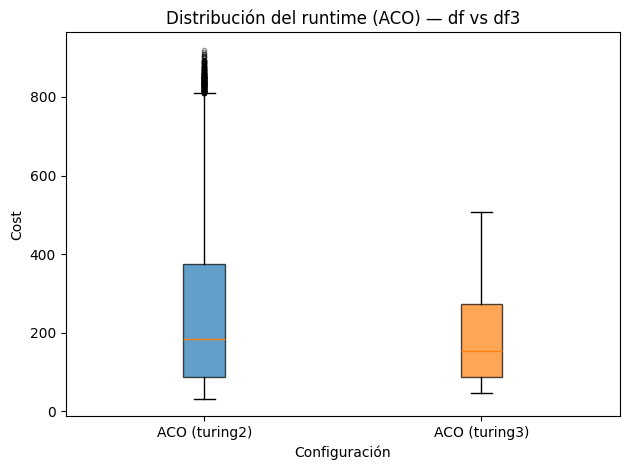

In [18]:
df3 = prepare_dataframe(filter_by_experiment_prefix(df=pre_filter_df, prefix="turing3"))

aco_feasible = df[(df["solver"] == "ACO") & (df["feasible"] == True)].copy()
aco_feasible3 = df3[(df3["solver"] == "ACO") & (df3["feasible"] == True)].copy()

fig, ax = plt.subplots()

data_list = [
    aco_feasible["cost"],
    aco_feasible3["cost"],
]

labels = [
    "ACO (turing2)",
    "ACO (turing3)",
]

colors = [
    "tab:blue",
    "tab:orange",
]

bp = ax.boxplot(
    data_list,
    labels=labels,
    patch_artist=True,
    flierprops=dict(marker="o", markersize=3, alpha=0.4),
)

for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_title("Distribución del runtime (ACO) — df vs df3")
ax.set_xlabel("Configuración")
ax.set_ylabel("Cost")

plt.tight_layout()
plt.show()

In [19]:
import numpy as np
from scipy import stats

# 🔹 filtrar datos
aco_base = df[(df["solver"] == "ACO") & (df["feasible"] == True)]["runtime"].values
aco_opt  = df3[(df3["solver"] == "ACO") & (df3["feasible"] == True)]["runtime"].values

# 🔹 métricas básicas
mean_base = np.mean(aco_base)
mean_opt  = np.mean(aco_opt)

std_base = np.std(aco_base)
std_opt  = np.std(aco_opt)

# 🔹 mejora
improvement_abs = mean_base - mean_opt
improvement_pct = (improvement_abs / mean_base) * 100

# 🔹 t-test (Welch, no asume misma varianza)
t_stat, p_value = stats.ttest_ind(aco_base, aco_opt, equal_var=False)

# 🔹 effect size (Cohen's d)
def cohens_d(x, y):
    nx, ny = len(x), len(y)
    pooled_std = np.sqrt(((nx - 1)*np.var(x) + (ny - 1)*np.var(y)) / (nx + ny - 2))
    return (np.mean(x) - np.mean(y)) / pooled_std

d = cohens_d(aco_base, aco_opt)

# 🔹 test no paramétrico (más robusto)
u_stat, p_value_mw = stats.mannwhitneyu(aco_base, aco_opt, alternative='two-sided')

# 📊 imprimir resultados
print("=== MÉTRICAS ===")
print(f"Base      → mean: {mean_base:.2f}, std: {std_base:.2f}")
print(f"Optimized → mean: {mean_opt:.2f}, std: {std_opt:.2f}")

print("\n=== MEJORA ===")
print(f"Abs improvement: {improvement_abs:.2f}")
print(f"% improvement:   {improvement_pct:.2f}%")

print("\n=== SIGNIFICANCIA ===")
print(f"T-test p-value: {p_value:.6f}")
print(f"Mann-Whitney p-value: {p_value_mw:.6f}")

print("\n=== EFFECT SIZE ===")
print(f"Cohen's d: {d:.3f}")

=== MÉTRICAS ===
Base      → mean: 37.22, std: 66.21
Optimized → mean: 28.95, std: 49.52

=== MEJORA ===
Abs improvement: 8.27
% improvement:   22.23%

=== SIGNIFICANCIA ===
T-test p-value: 0.528357
Mann-Whitney p-value: 0.915789

=== EFFECT SIZE ===
Cohen's d: 0.125
